# PhishGuard AI — phishing detection research

Question: How accurately can machine-learning models distinguish phishing from legitimate websites using URL-based features? The exact reference input is akashkr/phishing-website-dataset, version 2. Labels are verified in the source data card: −1 phishing, +1 legitimate. The data contain encoded features, not raw URLs. This notebook does not visit websites.

In [1]:
from pathlib import Path
import sys, json
root = Path.cwd()
if root.name == 'notebooks': root = root.parent
sys.path.insert(0, str(root / 'src'))
from preprocess import load_data, LEXICAL
raw, clean, features, sha256 = load_data()
print('Shape:', raw.shape, 'SHA-256:', sha256)
print(raw['Result'].value_counts())
raw.head()

Shape: (11055, 32) SHA-256: 83853a3ddf39a77e4bda0c8c907c5a7f521f16ed844299de75d215c22d5bd379
Result
 1    6157
-1    4898
Name: count, dtype: int64


,index,having_IPhaving_IP_Address,URLURL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,1,-1,1,1,1,-1,-1,-1,-1,-1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,2,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,3,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,4,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,5,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1


## Data exploration and provenance
The index is an identifier and never a predictor. Missing values and duplicates are measured before preprocessing. Source definitions are summarized in docs/feature-descriptions.json. Features such as certificate trust, page anchors, DNS and traffic require external observations.

In [2]:
print('Missing cells:', int(raw.isna().sum().sum()))
print('Exact duplicate rows:', int(raw.duplicated().sum()))
print('Duplicates excluding identifier:', len(raw)-len(clean))
print('Retained:', len(clean))
raw[features].describe().T

Missing cells: 0
Exact duplicate rows: 0
Duplicates excluding identifier: 5206
Retained: 5849


,count,mean,std,min,25%,50%,75%,max
having_IPhaving_IP_Address,11055.0,0.313795,0.949534,-1.0,-1.0,1.0,1.0,1.0
URLURL_Length,11055.0,-0.633198,0.766095,-1.0,-1.0,-1.0,-1.0,1.0
Shortining_Service,11055.0,0.738761,0.673998,-1.0,1.0,1.0,1.0,1.0
having_At_Symbol,11055.0,0.700588,0.713598,-1.0,1.0,1.0,1.0,1.0
double_slash_redirecting,11055.0,0.741474,0.671011,-1.0,1.0,1.0,1.0,1.0
Prefix_Suffix,11055.0,-0.734962,0.678139,-1.0,-1.0,-1.0,-1.0,1.0
having_Sub_Domain,11055.0,0.063953,0.817518,-1.0,-1.0,0.0,1.0,1.0
SSLfinal_State,11055.0,0.250927,0.911892,-1.0,-1.0,1.0,1.0,1.0
Domain_registeration_length,11055.0,-0.336771,0.941629,-1.0,-1.0,-1.0,1.0,1.0
Favicon,11055.0,0.628584,0.777777,-1.0,1.0,1.0,1.0,1.0


## Methods fixed before evaluation
Deduplicate identical feature-and-label rows, preserving contradictory labels. Group identical predictor patterns within each feature set. Use the first shuffled StratifiedGroupKFold split (5 folds, seed 42), giving approximately 80/20 train/test. Fit imputation and one-hot encoding inside each training pipeline. Encoded states are categorical; scaling arbitrary −1/0/+1 distances is not appropriate here. One-hot values are already on a common 0/1 scale. Apply balanced class weights only if the training class ratio exceeds 1.5. No test-driven hyperparameter tuning. Compare Logistic Regression (C=1) and Random Forest (250 trees, minimum leaf size 2).

In [3]:
from train import run
results = run()
import pandas as pd
rows=[]
for scope, exp in results['experiments'].items():
    print(scope, {k:v for k,v in exp['split'].items() if not k.endswith('source_ids')})
    for name, m in exp['models'].items():
        rows.append({'scope':scope,'model':name,**{k:m[k] for k in ['accuracy','precision','recall','f1','roc_auc']}})
pd.DataFrame(rows)

{
  "dataset": {
    "title": "Phishing website dataset",
    "creator": "Akash Kumar (akashkr)",
    "url": "https://www.kaggle.com/datasets/akashkr/phishing-website-dataset",
    "version": 2,
    "notebook": "https://www.kaggle.com/code/akashkr/phishing-url-eda-and-modelling/input",
    "sha256": "83853a3ddf39a77e4bda0c8c907c5a7f521f16ed844299de75d215c22d5bd379",
    "records": 11055,
    "columns": 32,
    "features": 30,
    "target": "Result",
    "labels": {
      "-1": "Phishing",
      "1": "Legitimate"
    },
    "missing": 0,
    "exact_duplicates": 0,
    "duplicates_without_index": 5206,
    "retained": 5849,
    "distribution": {
      "Phishing": 4898,
      "Legitimate": 6157
    }
  },
  "metrics": {
    "url": {
      "Logistic Regression": {
        "accuracy": 0.7876712328767124,
        "precision": 0.7621861152141802,
        "recall": 0.8557213930348259,
        "f1": 0.80625,
        "roc_auc": 0.8357049560457301,
        "confusion": [
          [
            4

,scope,model,accuracy,precision,recall,f1,roc_auc
0,url,Logistic Regression,0.787671,0.762186,0.855721,0.806250,0.835705
1,url,Random Forest,0.789384,0.766021,0.852405,0.806907,0.842253
2,full,Logistic Regression,0.936752,0.950680,0.925497,0.937919,0.987327
3,full,Random Forest,0.955556,0.966216,0.947020,0.956522,0.993938


## Measured charts
Raw distributions describe the source; correlation uses deduplicated encoded predictors. ROC and confusion matrices use held-out predictions with phishing as positive. Separate feature-set splits prevent shared feature patterns, but do not make the scopes a paired experiment.

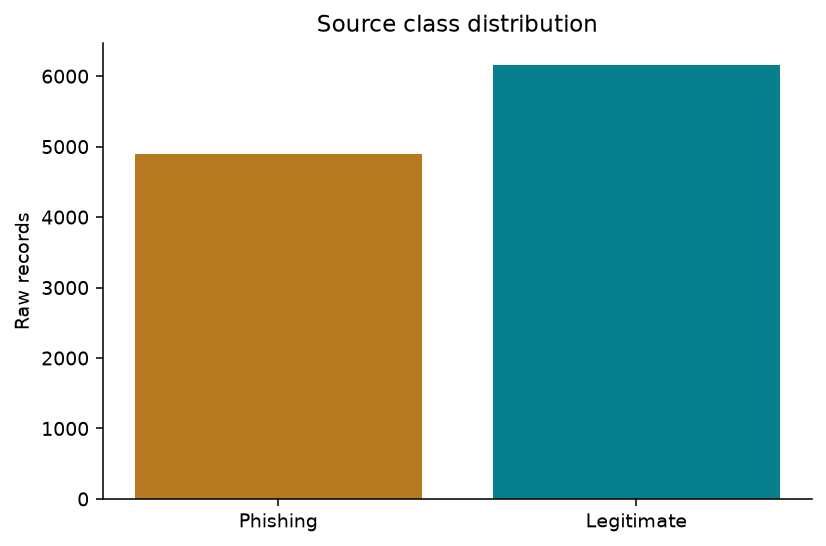

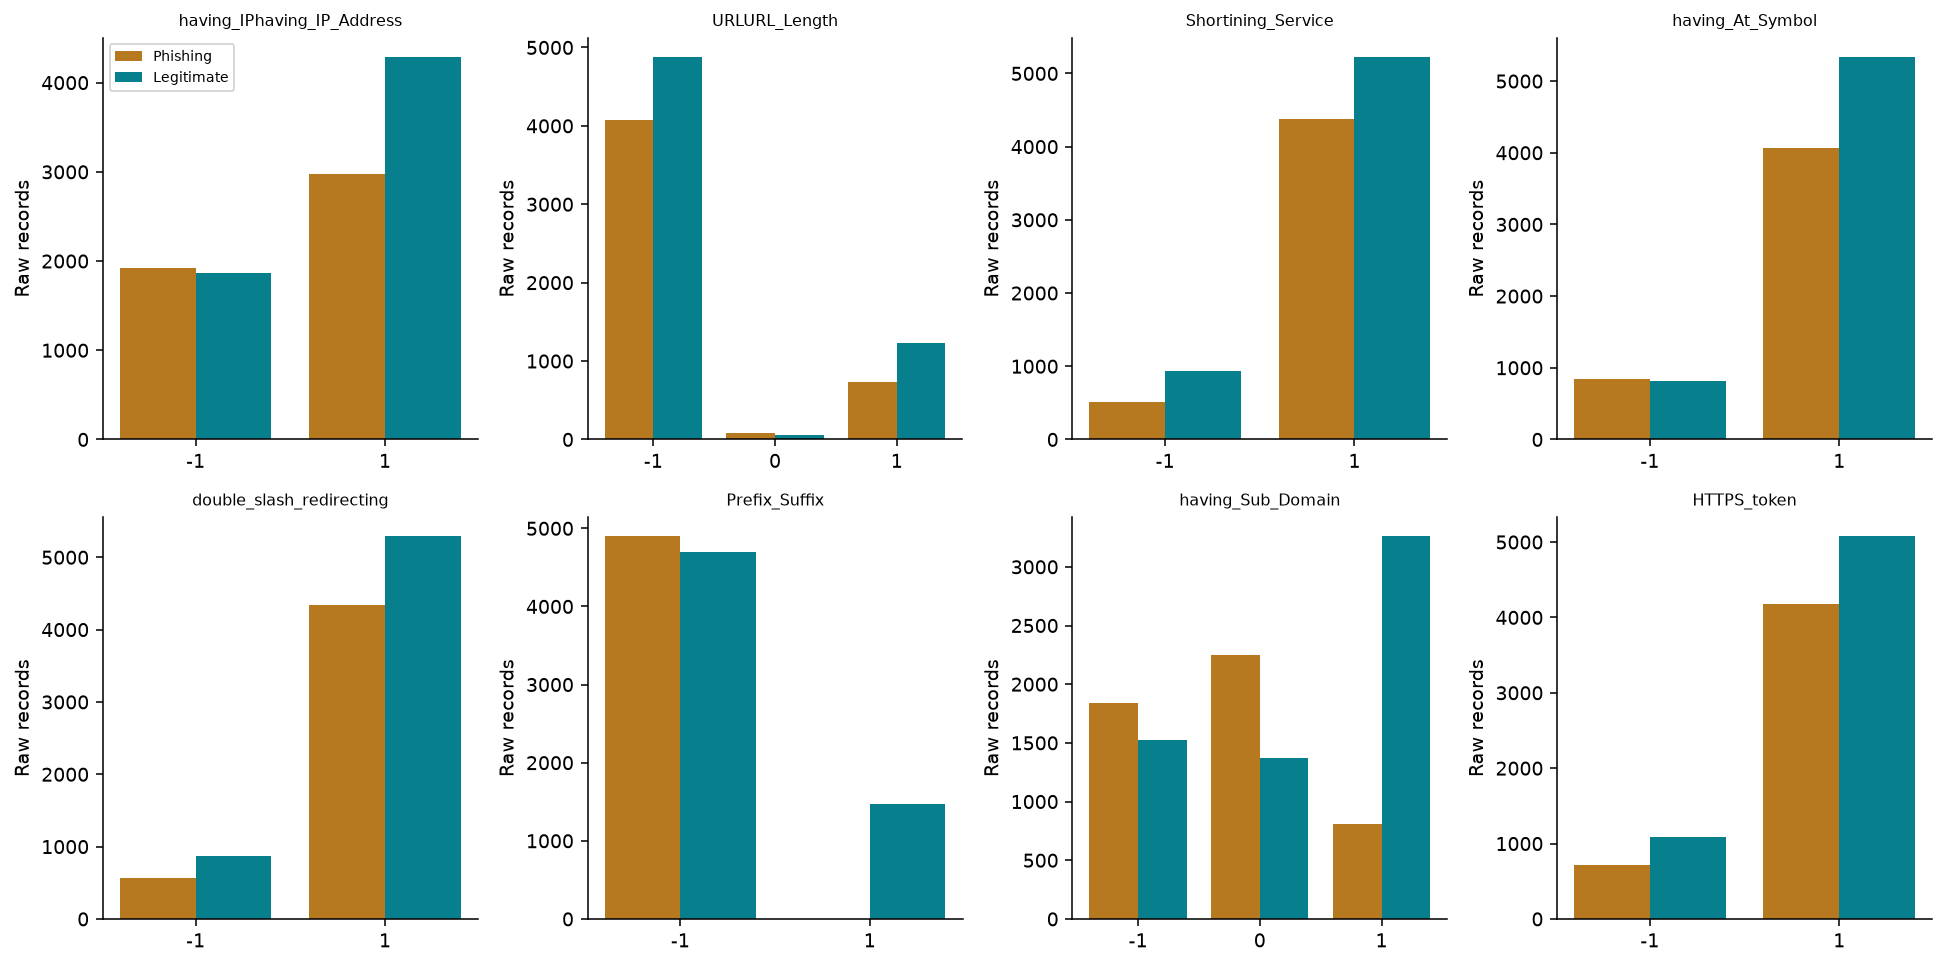

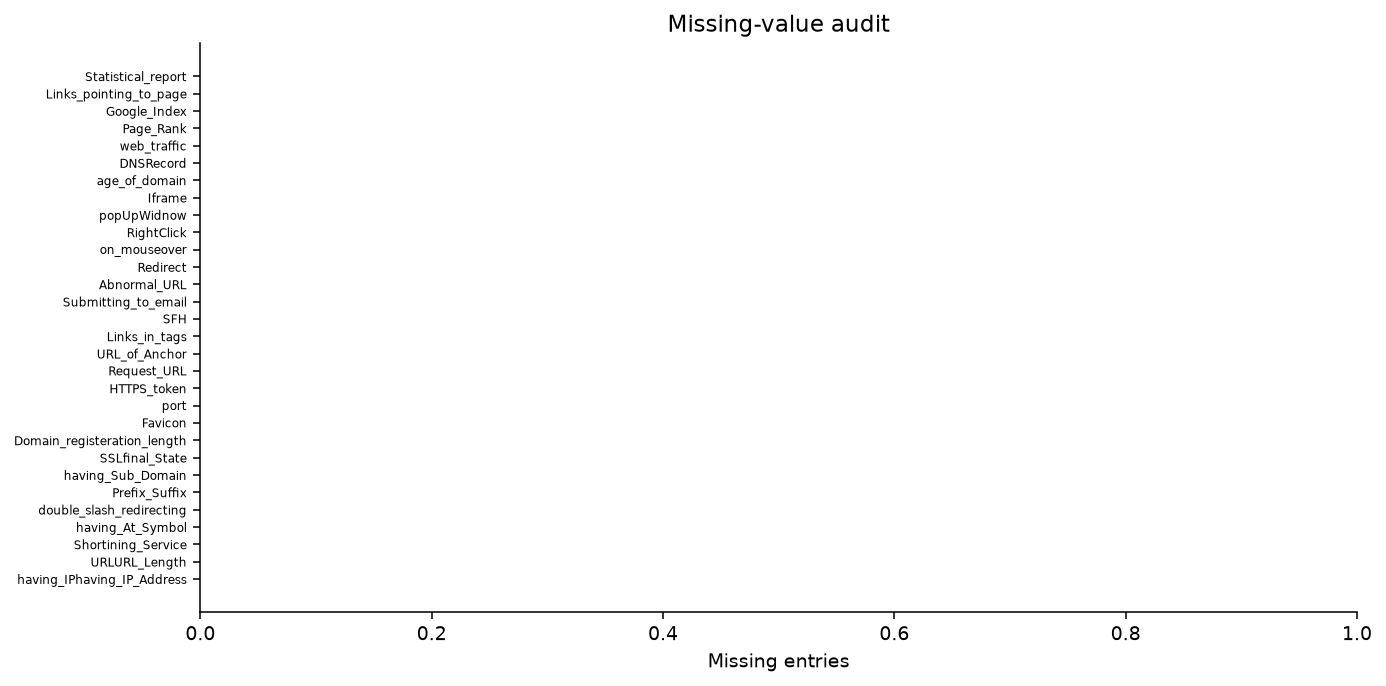

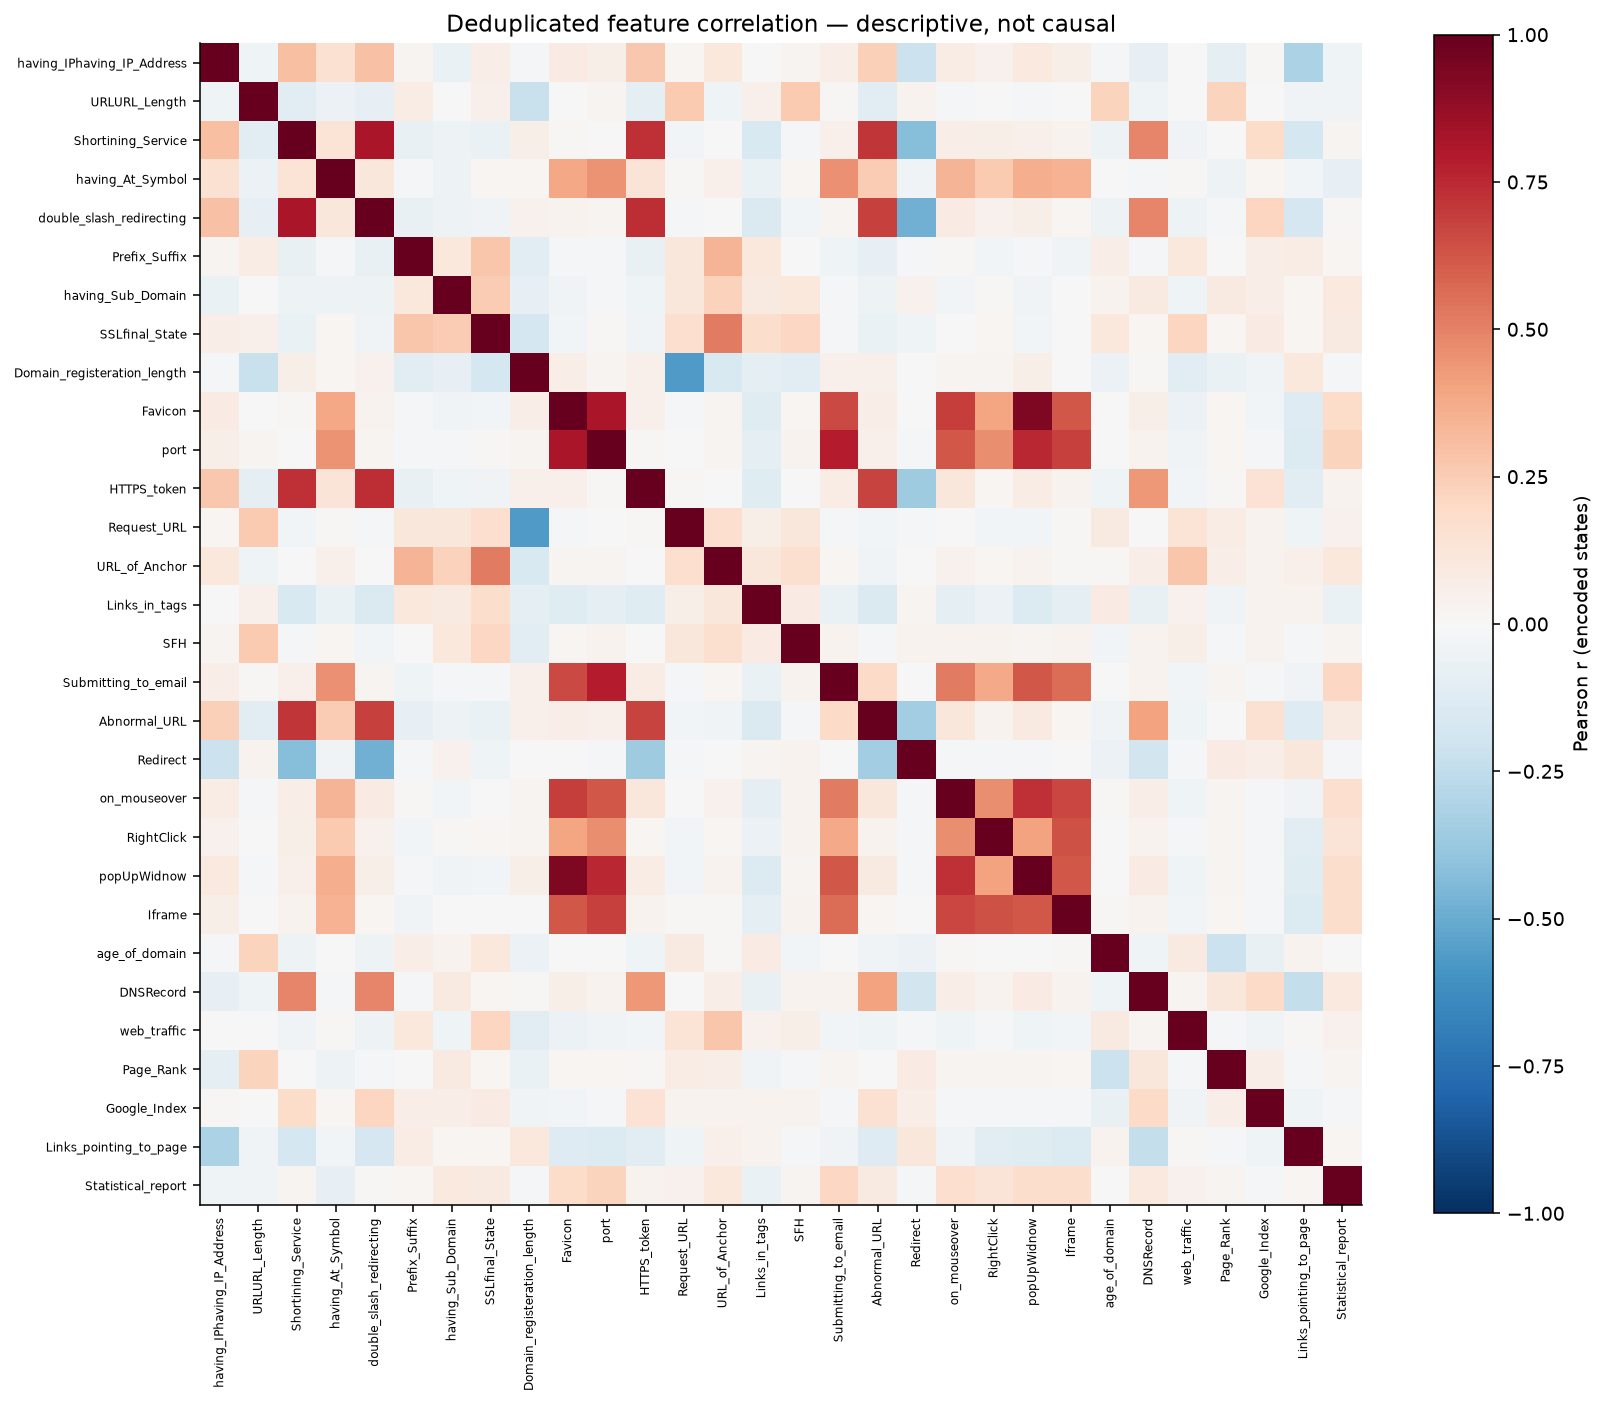

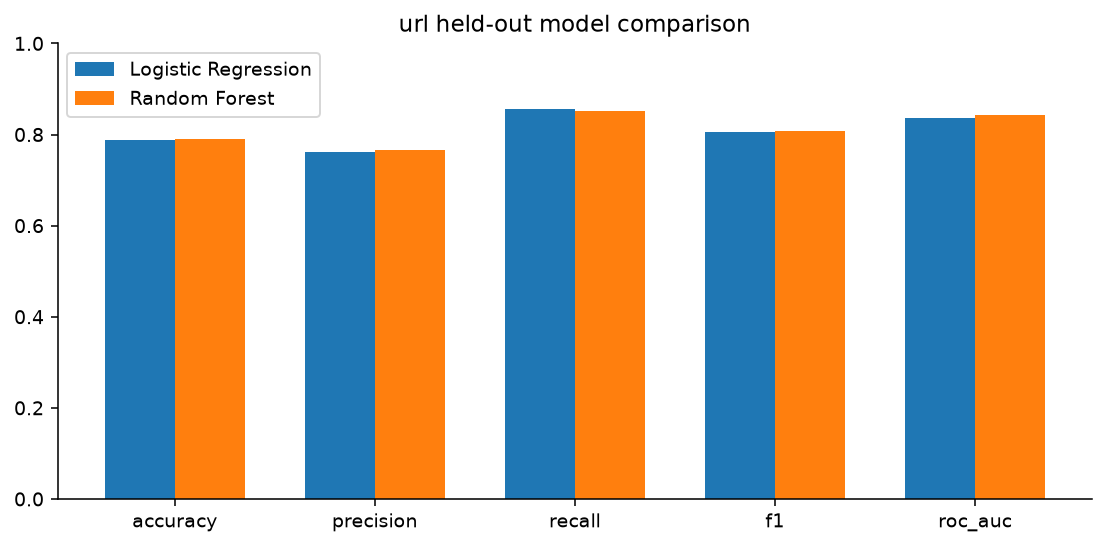

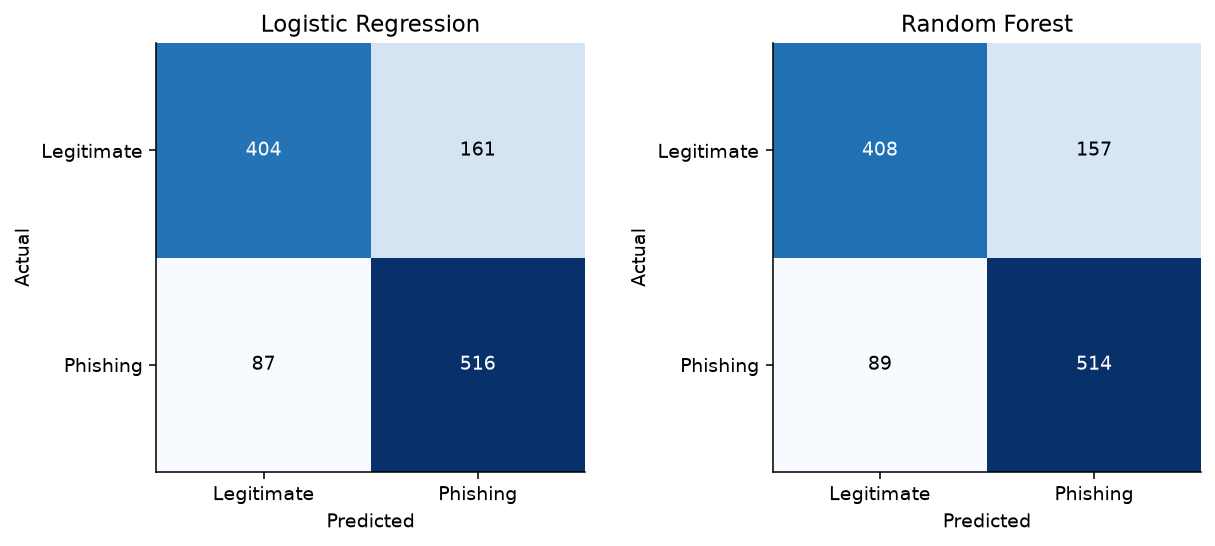

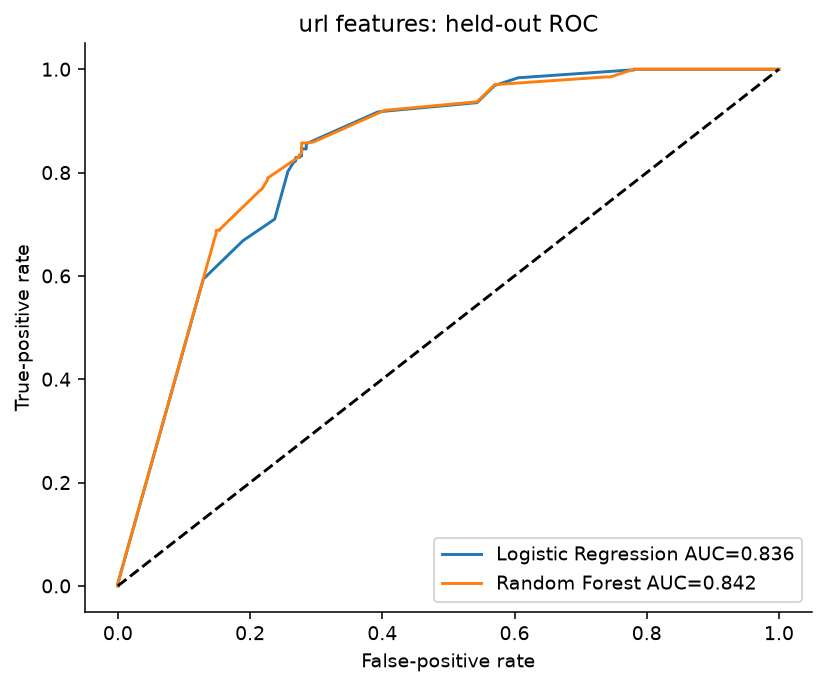

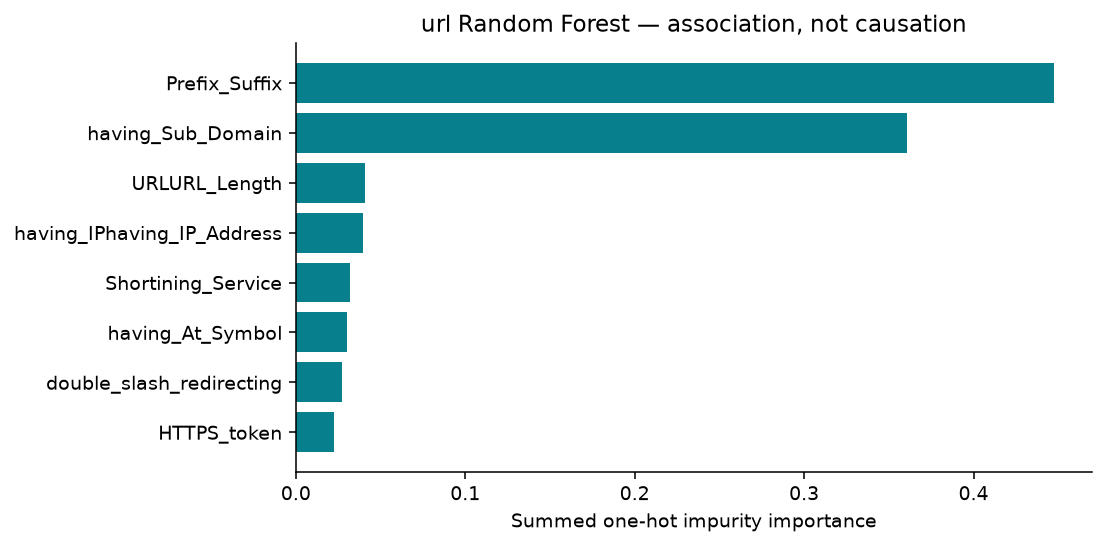

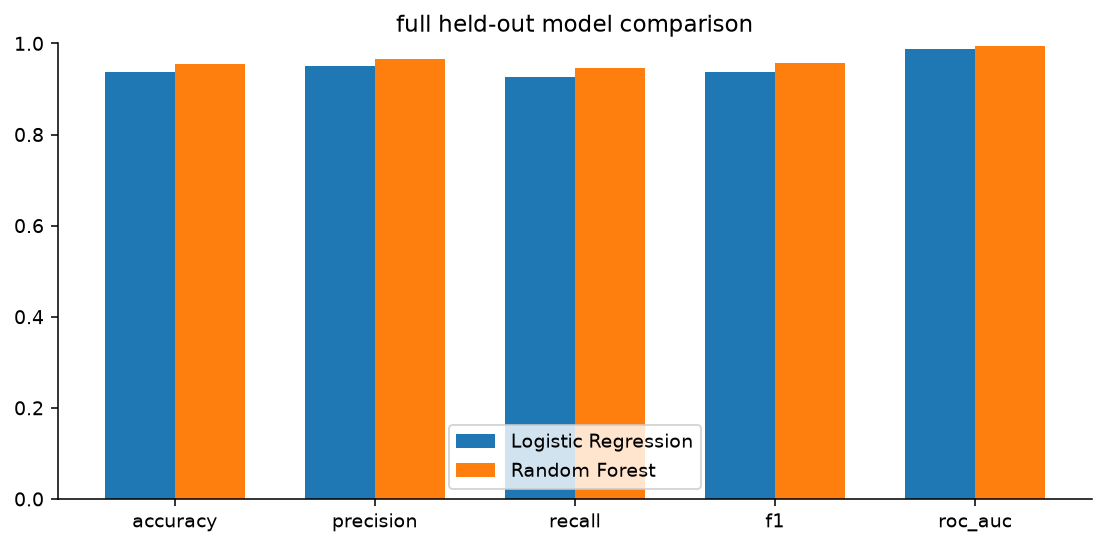

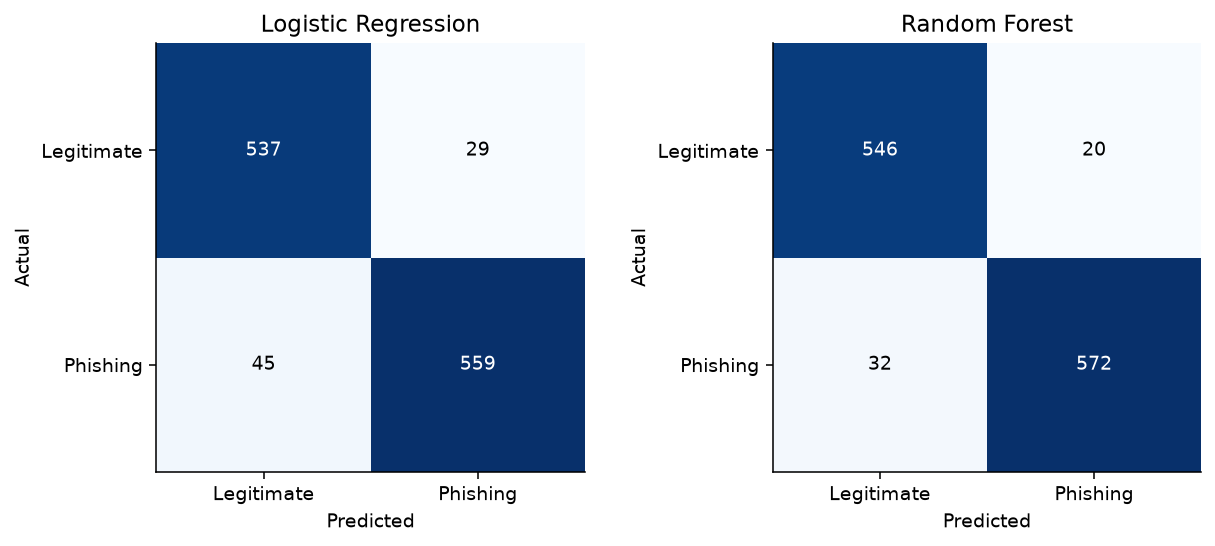

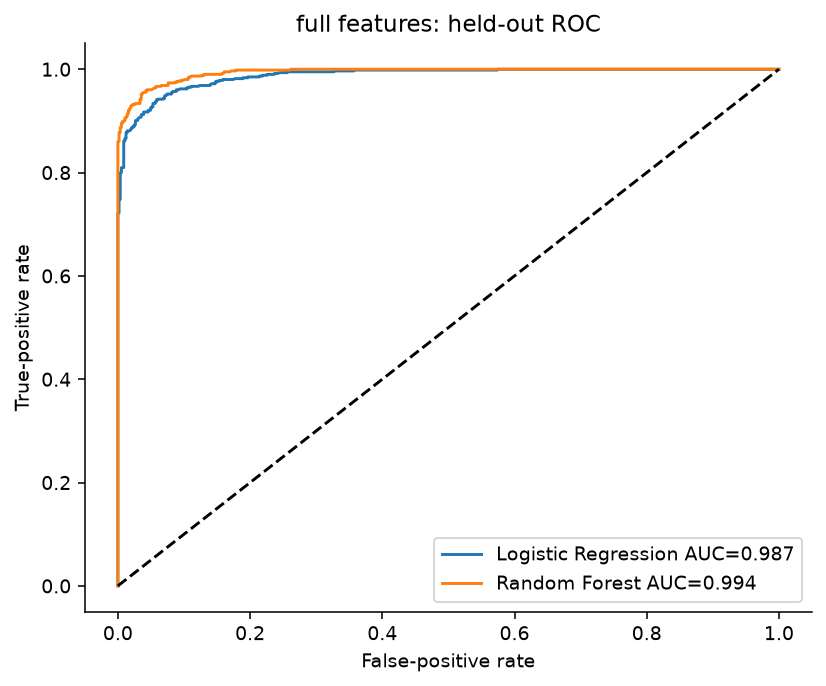

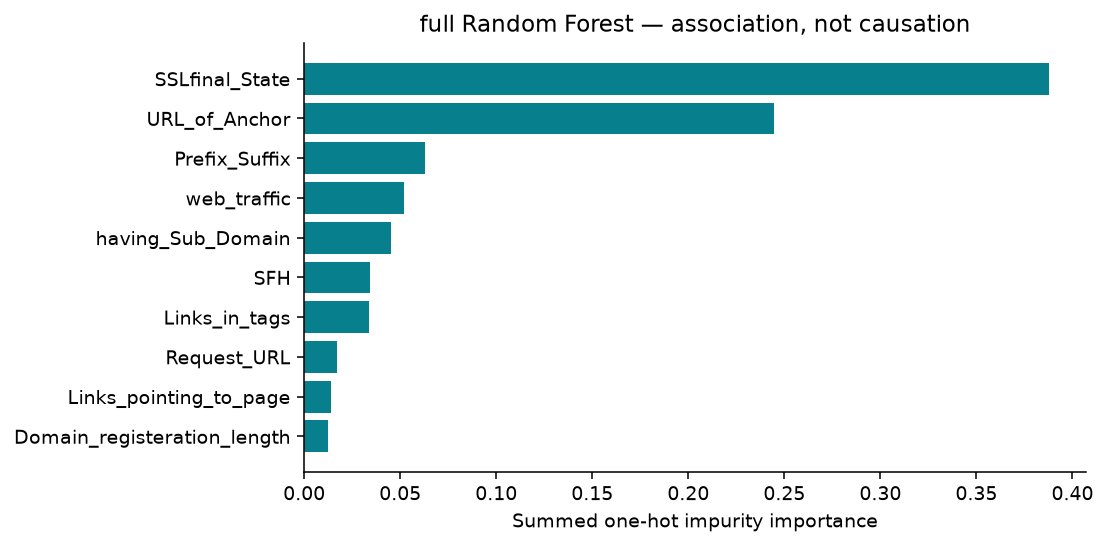

In [4]:
from IPython.display import display, Image
for name in ['classes','feature-distributions','missing','correlation','url-comparison','url-confusion','url-roc','url-importance','full-comparison','full-confusion','full-roc','full-importance']:
    display(Image(filename=str(root/'results'/'charts'/(name+'.png'))))

## Error inspection
False negatives miss phishing; false positives block legitimate records. Uncalibrated model probabilities are not confidence guarantees. Browse held-out mistakes without selecting them for training.

In [5]:
errors = [r for r in results['experiments']['url']['records'] if any(p['label'] != r['actual'] for p in r['predictions'].values())]
print('URL-scope records misclassified by at least one model:',len(errors))
errors[:3]

URL-scope records misclassified by at least one model: 251


[{'id': 80,
  'actual': 'Legitimate',
  'features': {'having_IPhaving_IP_Address': -1,
   'URLURL_Length': -1,
   'Shortining_Service': -1,
   'having_At_Symbol': 1,
   'double_slash_redirecting': -1,
   'Prefix_Suffix': -1,
   'having_Sub_Domain': -1,
   'HTTPS_token': -1},
  'predictions': {'Logistic Regression': {'label': 'Phishing',
    'phishing_probability': 0.7723624512138241},
   'Random Forest': {'label': 'Phishing',
    'phishing_probability': 0.7015587214908826}}},
 {'id': 117,
  'actual': 'Phishing',
  'features': {'having_IPhaving_IP_Address': -1,
   'URLURL_Length': 1,
   'Shortining_Service': -1,
   'having_At_Symbol': 1,
   'double_slash_redirecting': -1,
   'Prefix_Suffix': -1,
   'having_Sub_Domain': 1,
   'HTTPS_token': -1},
  'predictions': {'Logistic Regression': {'label': 'Legitimate',
    'phishing_probability': 0.33937386316043155},
   'Random Forest': {'label': 'Legitimate',
    'phishing_probability': 0.27971003298426106}}},
 {'id': 167,
  'actual': 'Legitimat

## Limitations and reproducibility
This historical snapshot lacks URLs, timestamps and domain groups. Pattern grouping addresses exact duplicates, not related-domain or temporal leakage. Categorical feature definitions include older reputation signals and incomplete extraction rules. A single holdout gives no confidence interval. Do not deploy this as a live safety checker. See docs/report.md for interpretation and references. Run src/export_site.py after the analysis to embed current results in the existing HTML.

In [6]:
assert all(e['split']['group_overlap']==0 for e in results['experiments'].values())
assert all(sum(map(sum,m['confusion']))==e['split']['test'] for e in results['experiments'].values() for m in e['models'].values())
print('Verified: no shared predictor groups; confusion totals match test sizes.')

Verified: no shared predictor groups; confusion totals match test sizes.
